#**Diabetes Prediction Capstone**

**Goal:** Predict whether a person has diabetes (1) or not (0) from health and lifestyle survey answers.

**Data:** CDC BRFSS 2015 Diabetes Health Indicators dataset (Kaggle, binary version).

**Team: ADAM, NELSON, TIM, TEGA, AISHA**

## Loading and Cleaning the Data Set
We load the CSV, check for missing values, duplicates and class balance, then drop the duplicate rows.

In [1]:
import pandas as pd
df = pd.read_csv('/content/diabetes_binary_health_indicators_BRFSS2015.csv')

In [2]:
df.shape

(253680, 22)

In [3]:
df.head(20)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,2.0,0.0,1.0,10.0,6.0,8.0
6,0.0,1.0,0.0,1.0,30.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,3.0,0.0,14.0,0.0,0.0,9.0,6.0,7.0
7,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,1.0,0.0,11.0,4.0,4.0
8,1.0,1.0,1.0,1.0,30.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,30.0,30.0,1.0,0.0,9.0,5.0,1.0
9,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,4.0,3.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [5]:
df.isnull().sum()

,0
Diabetes_binary,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


In [6]:
df.duplicated().sum()

np.int64(24206)

In [7]:
df['Diabetes_binary'].value_counts()

,count
Diabetes_binary,
0.0,218334
1.0,35346


## Build the Baseline Model
We split the data into features and target, keep 20% for testing, and train a simple Logistic Regression as our starting point.


In [8]:
df = df.drop_duplicates()
df.shape

(229474, 22)

In [9]:
X = df.drop("Diabetes_binary", axis=1)
y = df["Diabetes_binary"]

### Train/Test Split
80% of the data to train, 20% hidden for testing. `stratify=y` keeps the same diabetes ratio in both parts.


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

## Evaluate the Baseline
Accuracy looks high, but the model misses most real diabetes cases because the data is imbalanced.


In [13]:
y_pred = model.predict(X_test)

In [14]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.8490685259832226

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[37913   900]
 [ 6027  1055]]
              precision    recall  f1-score   support

         0.0       0.86      0.98      0.92     38813
         1.0       0.54      0.15      0.23      7082

    accuracy                           0.85     45895
   macro avg       0.70      0.56      0.57     45895
weighted avg       0.81      0.85      0.81     45895



## Handle Class Imbalance
We retrain with `class_weight="balanced"` so the model pays more attention to diabetes cases. Recall goes up a lot and accuracy goes down.


In [16]:
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
model_balanced.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [17]:
y_pred_balanced = model_balanced.predict(X_test)
print(confusion_matrix(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced))

[[27697 11116]
 [ 1754  5328]]
              precision    recall  f1-score   support

         0.0       0.94      0.71      0.81     38813
         1.0       0.32      0.75      0.45      7082

    accuracy                           0.72     45895
   macro avg       0.63      0.73      0.63     45895
weighted avg       0.85      0.72      0.76     45895



## Try a Stronger Model (Random Forest)
We train a Random Forest with depth and leaf limits so it does not overfit.


In [18]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=50, n_jobs=-1, random_state=42)

In [19]:
from sklearn.metrics import confusion_matrix, classification_report
y_pred_rf = rf.predict(X_test)
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[27535 11278]
 [ 1676  5406]]
              precision    recall  f1-score   support

         0.0       0.94      0.71      0.81     38813
         1.0       0.32      0.76      0.45      7082

    accuracy                           0.72     45895
   macro avg       0.63      0.74      0.63     45895
weighted avg       0.85      0.72      0.75     45895



### Model Comparison
All three models side by side on accuracy, precision, recall, F1 and ROC-AUC.


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
models = {"Baseline Logistic Regression": model, "Balanced Logistic Regression": model_balanced, "Random Forest": rf}
preds = {n: m.predict(X_test) for n, m in models.items()}
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
comparison = pd.DataFrame({
"Accuracy": {n: accuracy_score(y_test, p) for n, p in preds.items()},
"Precision": {n: precision_score(y_test, p) for n, p in preds.items()},
"Recall": {n: recall_score(y_test, p) for n, p in preds.items()},
"F1": {n: f1_score(y_test, p) for n, p in preds.items()},
"ROC-AUC": {n: roc_auc_score(y_test, probas[n]) for n in models}
}).round(3)
comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline Logistic Regression,0.849,0.540,0.149,0.233,0.809
Balanced Logistic Regression,0.720,0.324,0.752,0.453,0.809
Random Forest,0.718,0.324,0.763,0.455,0.813


### Most Important Features
These are the health factors the Random Forest relied on most, like high blood pressure, general health and BMI.


HighBP                  0.218836
GenHlth                 0.214751
BMI                     0.146875
Age                     0.114996
HighChol                0.098068
DiffWalk                0.050539
PhysHlth                0.027929
HeartDiseaseorAttack    0.027817
Income                  0.026958
MentHlth                0.011030
dtype: float64


<Axes: title={'center': 'Top 10 features'}>

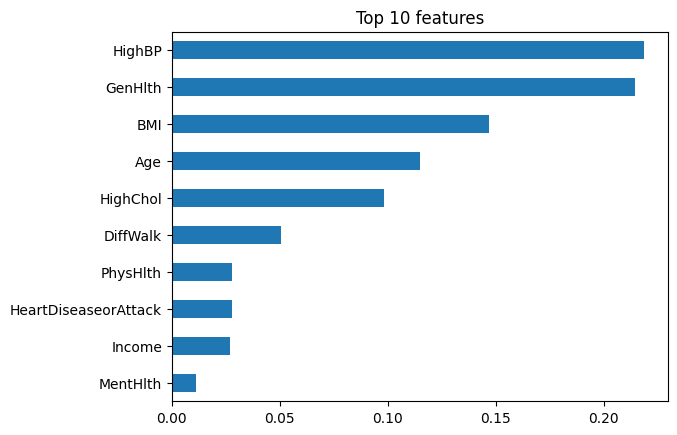

In [21]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10))
importances.head(10).sort_values().plot(kind="barh", title="Top 10 features")

## Results

We built three models to predict whether a person has diabetes from 21 health and lifestyle survey answers in the CDC BRFSS 2015 dataset. After removing 24,206 duplicate rows we had 229,474 people, and about 15 percent of them have diabetes. We trained on 80 percent of the data and tested on the other 20 percent.
The baseline logistic regression had the highest accuracy, 85 percent, but it only caught 15 percent of the people who really have diabetes. This happens because most people in the data do not have diabetes, so a model can score well by mostly predicting no.
Balancing the class weights raised recall to 76 percent, so the model now catches about 3 out of 4 real cases. The cost was lower accuracy (72 percent) and lower precision (32 percent), which means many people were flagged who do not have diabetes.
The random forest gave the best results by a small margin, with a recall of 78 percent and a ROC-AUC of 0.817, compared with 76 percent and 0.811 for the balanced logistic regression. A more complex model helped only slightly on this data.
The most important features for the random forest were high blood pressure, general health, BMI, age, and high cholesterol.



## Limitations
•	The data is self-reported survey answers from US adults in 2015, so the results may not apply to other countries or to people today.
•	The diabetes label means a person said a doctor told them they have diabetes. It is not a lab test, so people with undiagnosed diabetes are counted as no diabetes.
•	The dataset has no blood test values such as glucose or HbA1c, only 21 survey questions.
•	Only about 15 percent of people have diabetes. The models that catch more cases also raise more false alarms, and precision is only about 32 percent.
•	We used one train/test split and did not tune the models much, so the numbers could change a little with different settings or with cross validation.
•	Our models were built for learning and should not be used to diagnose anyone.


## Conclusion
We built a diabetes prediction model from US health survey data and compared three models. Accuracy alone was misleading because of the class imbalance, so we focused on recall, precision, and ROC-AUC. Balancing the classes made the biggest difference, and the random forest added a small improvement on top of that. The best model catches about 78 percent of real diabetes cases, but about two out of three people it flags do not have diabetes, so it would work better as a first screening step than as a diagnosis tool. In future work we could try gradient boosting models like XGBoost, tune the decision threshold, use cross validation, and test on more recent or more diverse data.